# Negócio

**Pergunta:** com capacidade limitada de revisão, quais transações revisar para maximizar o valor de fraude capturado?

**O que este notebook compara:**
1. **Duas filas:** ordenar pela chance de fraude, `P(fraude)`, ou pelo valor esperado de fraude, `P(fraude) × valor`.
2. **Valor líquido:** fraude capturada menos o custo das revisões, com o custo como premissa (D19).
3. **Limiar:** em vez de uma capacidade fixa, revisar toda compra em que o valor esperado de fraude supera o custo de revisão.

**Dados:** tudo é medido na 2ª metade da validação, que a calibração não usou (D17). O teste não entra em nenhum cálculo.

**Premissas (não vêm dos dados):** revisar uma fraude evita 100% do valor dela. Revisar uma compra legítima custa só o custo de revisão. Os valores estão em unidades monetárias da base, que não informa a moeda.

In [1]:
from pathlib import Path
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.linear_model import LogisticRegression

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
from divisao_temporal import calcular_cortes, dividir_por_tempo
from metricas import selecionar_revisadas, valor_capturado
from modelo import treinar_lightgbm

ARQUIVO = RAIZ / "data" / "processed" / "treino.parquet"
nomes = pq.ParquetFile(ARQUIVO).schema_arrow.names
COLUNAS_C = [n for n in nomes if re.fullmatch(r"C\d+", n)]
COLUNAS_ID = [n for n in nomes if re.fullmatch(r"id_\d+", n)]
COLUNAS_BASE = [
    "TransactionAmt", "tem_identidade", "ProductCD", "card4", "card6",
    "card1", "card2", "card3", "card5", "addr1", "addr2", "dist1", "dist2",
    "P_emaildomain", "R_emaildomain",
]

tabela = pd.read_parquet(
    ARQUIVO,
    columns=["TransactionDT", "isFraud", *[c for c in COLUNAS_BASE if c != "tem_identidade"], *COLUNAS_C, *COLUNAS_ID],
)
tabela["tem_identidade"] = tabela[COLUNAS_ID].notna().any(axis=1).astype("int8")
tabela = tabela.drop(columns=COLUNAS_ID)

corte_treino, corte_validacao = calcular_cortes(tabela["TransactionDT"])
treino, validacao, _ = dividir_por_tempo(tabela, corte_treino, corte_validacao)
del _, tabela  # o teste sai da memória antes de qualquer treino ou medição

corte_metade, _ = calcular_cortes(validacao["TransactionDT"], fracao_treino=0.5, fracao_validacao=0.5)
calibra, mede, _ = dividir_por_tempo(validacao, corte_metade, validacao["TransactionDT"].max())
del _, validacao

rotulos = mede["isFraud"].astype("int8")
valores = mede["TransactionAmt"].astype("float64")
fraude_total = float(valores[rotulos == 1].sum())
print(f"2ª metade: {len(mede):,} compras | {int(rotulos.sum()):,} fraudes | valor total de fraude: {fraude_total:,.2f}")

2ª metade: 59,054 compras | 2,061 fraudes | valor total de fraude: 356,581.77


## 1. Modelos calibrados

Mesmo treino do notebook 05 e mesma calibração de Platt do notebook 06. A probabilidade calibrada é a base das duas filas.

In [2]:
def logit(p: np.ndarray) -> np.ndarray:
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


probabilidade = {}
for nome, colunas in [("com C", [*COLUNAS_BASE, *COLUNAS_C]), ("sem C", COLUNAS_BASE)]:
    modelo, arvores = treinar_lightgbm(treino, colunas)
    platt = LogisticRegression(C=1e10).fit(logit(modelo.predict(calibra[colunas])), calibra["isFraud"])
    probabilidade[nome] = pd.Series(platt.predict_proba(logit(modelo.predict(mede[colunas])))[:, 1], index=mede.index)
    print(f"LightGBM {nome}: {arvores} árvores")

filas = {"Regra por valor": valores}
for nome, p in probabilidade.items():
    filas[f"LightGBM {nome}, P(fraude)"] = p
    filas[f"LightGBM {nome}, P(fraude) × valor"] = p * valores

LightGBM com C: 712 árvores


LightGBM sem C: 344 árvores


## 2. Qual fila captura mais valor?

Mesma capacidade para todas as filas. Precisão é a parte das compras revisadas que era fraude. Valor capturado é a parte do valor total de fraude que estava nas compras revisadas.

In [3]:
linhas = []
for nome, pontuacao in filas.items():
    for capacidade in [0.005, 0.01, 0.03, 0.05]:
        revisadas = selecionar_revisadas(pontuacao, capacidade)
        linhas.append(
            {
                "Fila": nome,
                "Capacidade (%)": 100 * capacidade,
                "Precisão (%)": 100 * rotulos.loc[revisadas].mean(),
                "Valor capturado (%)": valor_capturado(rotulos, pontuacao, valores, capacidade),
            }
        )
por_capacidade = pd.DataFrame(linhas).set_index(["Fila", "Capacidade (%)"]).round(2)
por_capacidade.unstack("Capacidade (%)")

Precisão (%)                       \
Capacidade (%)                             0.5    1.0    3.0    5.0   
Fila                                                                  
LightGBM com C, P(fraude)                88.51  89.85  59.65  42.16   
LightGBM com C, P(fraude) × valor        62.50  61.25  43.85  35.02   
LightGBM sem C, P(fraude)                56.42  49.58  36.51  28.41   
LightGBM sem C, P(fraude) × valor        38.18  31.81  21.33  18.02   
Regra por valor                           3.72   3.55   6.88   7.86   

                                  Valor capturado (%)                       
Capacidade (%)                                    0.5    1.0    3.0    5.0  
Fila                                                                        
LightGBM com C, P(fraude)                        6.92  17.93  42.36  52.82  
LightGBM com C, P(fraude) × valor               30.79  38.23  57.48  66.80  
LightGBM sem C, P(fraude)                        6.95  12.04  23.96  32.19  
LightGBM sem C, P(fraude) × valor               20.72  28.93  44.68  54.47  
Regra por valor                                  8.78  12.65  36.96  52.06

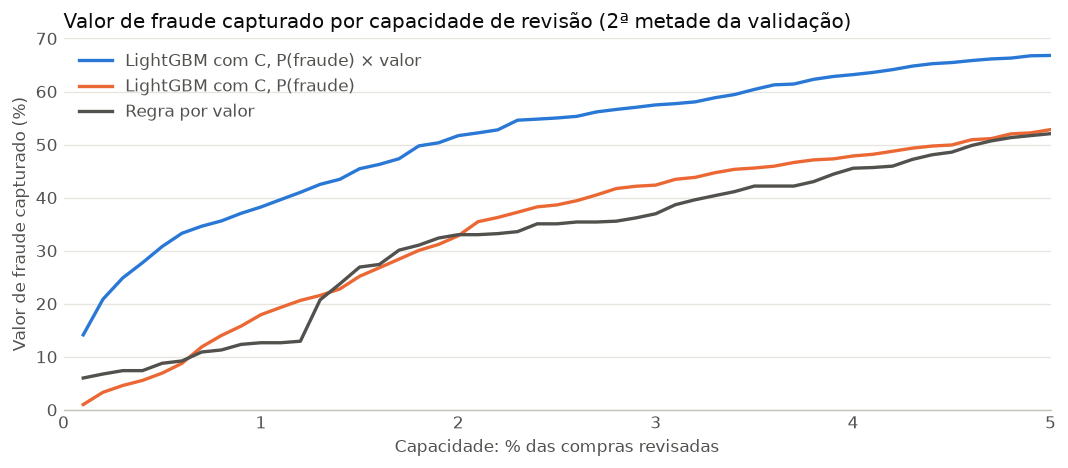

In [4]:
capacidades = np.arange(0.001, 0.0501, 0.001)
series = [
    ("LightGBM com C, P(fraude) × valor", "#2a78d6"),
    ("LightGBM com C, P(fraude)", "#eb6834"),
    ("Regra por valor", "#52514e"),
]
fig, ax = plt.subplots(figsize=(9, 4), dpi=120)
for nome, cor in series:
    curva = [valor_capturado(rotulos, filas[nome], valores, c) for c in capacidades]
    ax.plot(100 * capacidades, curva, color=cor, linewidth=2, label=nome)
ax.set_title("Valor de fraude capturado por capacidade de revisão (2ª metade da validação)", loc="left", color="#0b0b0b")
ax.set_xlabel("Capacidade: % das compras revisadas", color="#52514e")
ax.set_ylabel("Valor de fraude capturado (%)", color="#52514e")
ax.set_xlim(0, 5)
ax.set_ylim(bottom=0)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors="#52514e", length=0)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.legend(frameon=False, labelcolor="#52514e")
fig.tight_layout()
fig.savefig(RAIZ / "reports" / "figures" / "valor_capturado_por_capacidade.png", bbox_inches="tight")
plt.show()

## 3. Valor líquido sob custos de revisão (premissa)

**Valor líquido = valor de fraude capturado − custo por revisão × número de revisões.**

O custo por revisão é uma premissa (D19), testada em 1, 5, 10, 20 e 50. Para comparação, a mediana do valor das compras no treino é 70,00.

Duas formas de decidir quantas compras revisar:
- **Capacidade fixa de 3%:** revisa sempre 3% das compras, qualquer que seja o custo.
- **Limiar:** revisa toda compra em que `P(fraude) × valor` supera o custo de revisão. O número de revisões muda com o custo. Esse limiar só faz sentido com a probabilidade calibrada, porque compara uma estimativa de dinheiro com um custo em dinheiro.

In [5]:
CUSTOS = [1, 5, 10, 20, 50]


def resultado(revisadas: pd.Index, custo: float) -> dict:
    capturado = float(valores.loc[revisadas][rotulos.loc[revisadas] == 1].sum())
    return {
        "Revisões": len(revisadas),
        "Capturado": capturado,
        "Custo das revisões": custo * len(revisadas),
        "Valor líquido": capturado - custo * len(revisadas),
    }


linhas = []
for custo in CUSTOS:
    for nome in ["Regra por valor", "LightGBM com C, P(fraude)", "LightGBM com C, P(fraude) × valor", "LightGBM sem C, P(fraude) × valor"]:
        linhas.append({"Custo por revisão": custo, "Estratégia": f"{nome}, 3%", **resultado(selecionar_revisadas(filas[nome], 0.03), custo)})
    for nome in ["com C", "sem C"]:
        esperado = filas[f"LightGBM {nome}, P(fraude) × valor"]
        linhas.append({"Custo por revisão": custo, "Estratégia": f"LightGBM {nome}, limiar", **resultado(esperado.index[esperado > custo], custo)})

valor_liquido = pd.DataFrame(linhas)
print(f"Valor total de fraude na 2ª metade: {fraude_total:,.2f}")
valor_liquido.set_index(["Custo por revisão", "Estratégia"]).round(0)

Valor total de fraude na 2ª metade: 356,581.77


Revisões  Capturado  \
Custo por revisão Estratégia                                                   
1                 Regra por valor, 3%                        1772   131795.0   
                  LightGBM com C, P(fraude), 3%              1772   151066.0   
                  LightGBM com C, P(fraude) × valor, 3%      1772   204963.0   
                  LightGBM sem C, P(fraude) × valor, 3%      1772   159336.0   
                  LightGBM com C, limiar                    23764   346384.0   
                  LightGBM sem C, limiar                    32001   344983.0   
5                 Regra por valor, 3%                        1772   131795.0   
                  LightGBM com C, P(fraude), 3%              1772   151066.0   
                  LightGBM com C, P(fraude) × valor, 3%      1772   204963.0   
                  LightGBM sem C, P(fraude) × valor, 3%      1772   159336.0   
                  LightGBM com C, limiar                     8660   305896.0   
                  LightGBM sem C, limiar                    11642   293913.0   
10                Regra por valor, 3%                        1772   131795.0   
                  LightGBM com C, P(fraude), 3%              1772   151066.0   
                  LightGBM com C, P(fraude) × valor, 3%      1772   204963.0   
                  LightGBM sem C, P(fraude) × valor, 3%      1772   159336.0   
                  LightGBM com C, limiar                     4943   272045.0   
                  LightGBM sem C, limiar                     6239   244965.0   
20                Regra por valor, 3%                        1772   131795.0   
                  LightGBM com C, P(fraude), 3%              1772   151066.0   
                  LightGBM com C, P(fraude) × valor, 3%      1772   204963.0   
                  LightGBM sem C, P(fraude) × valor, 3%      1772   159336.0   
                  LightGBM com C, limiar                     2692   234133.0   
                  LightGBM sem C, limiar                     2802   192170.0   
50                Regra por valor, 3%                        1772   131795.0   
                  LightGBM com C, P(fraude), 3%              1772   151066.0   
                  LightGBM com C, P(fraude) × valor, 3%      1772   204963.0   
                  LightGBM sem C, P(fraude) × valor, 3%      1772   159336.0   
                  LightGBM com C, limiar                      963   166513.0   
                  LightGBM sem C, limiar                      738   115304.0   

                                                         Custo das revisões  \
Custo por revisão Estratégia                                                  
1                 Regra por valor, 3%                                  1772   
                  LightGBM com C, P(fraude), 3%                        1772   
                  LightGBM com C, P(fraude) × valor, 3%                1772   
                  LightGBM sem C, P(fraude) × valor, 3%                1772   
                  LightGBM com C, limiar                              23764   
                  LightGBM sem C, limiar                              32001   
5                 Regra por valor, 3%                                  8860   
                  LightGBM com C, P(fraude), 3%                        8860   
                  LightGBM com C, P(fraude) × valor, 3%                8860   
                  LightGBM sem C, P(fraude) × valor, 3%                8860   
                  LightGBM com C, limiar                              43300   
                  LightGBM sem C, limiar                              58210   
10                Regra por valor, 3%                                 17720   
                  LightGBM com C, P(fraude), 3%                       17720   
                  LightGBM com C, P(fraude) × valor, 3%               17720   
                  LightGBM sem C, P(fraude) × valor, 3%               17720   
                  LightGBM com C, limiar                              4943

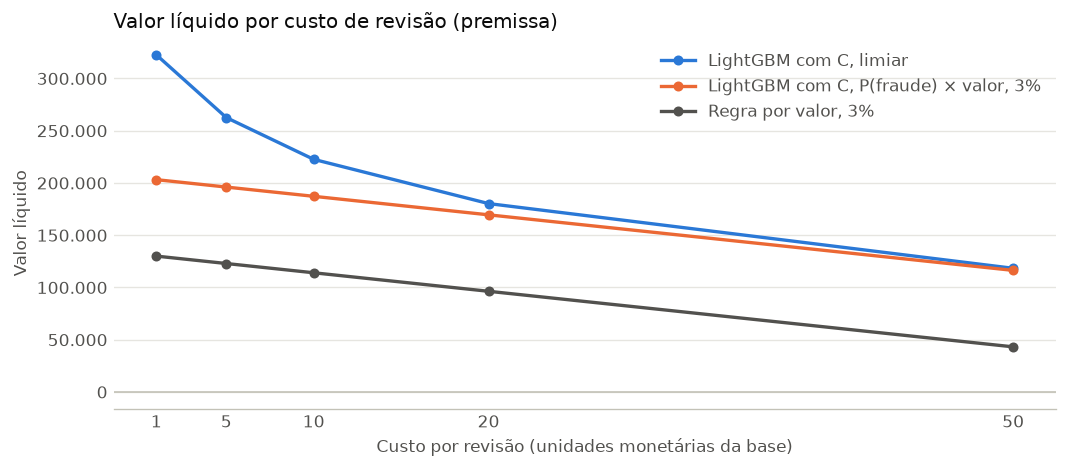

In [6]:
series = [
    ("LightGBM com C, limiar", "#2a78d6"),
    ("LightGBM com C, P(fraude) × valor, 3%", "#eb6834"),
    ("Regra por valor, 3%", "#52514e"),
]
fig, ax = plt.subplots(figsize=(9, 4), dpi=120)
for nome, cor in series:
    dados = valor_liquido[valor_liquido["Estratégia"] == nome]
    ax.plot(dados["Custo por revisão"], dados["Valor líquido"], color=cor, linewidth=2, marker="o", markersize=5, label=nome)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_title("Valor líquido por custo de revisão (premissa)", loc="left", color="#0b0b0b")
ax.set_xlabel("Custo por revisão (unidades monetárias da base)", color="#52514e")
ax.set_ylabel("Valor líquido", color="#52514e")
ax.set_xticks(CUSTOS)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: f"{valor:,.0f}".replace(",", ".")))
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors="#52514e", length=0)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.legend(frameon=False, labelcolor="#52514e")
fig.tight_layout()
fig.savefig(RAIZ / "reports" / "figures" / "valor_liquido_por_custo.png", bbox_inches="tight")
plt.show()

## Conclusões de negócio

- Ordenar por valor esperado de fraude, `P(fraude) × valor`, captura mais dinheiro do que ordenar só pela chance de fraude. Revisando 3% das compras com o LightGBM com C, o valor capturado sobe de 42,36% para 57,48%, e a precisão cai de 59,65% para 43,85%. A fila por chance acerta mais fraudes, mas muitas são de valor baixo. A fila por valor esperado aceita revisar mais compras legítimas para alcançar as fraudes de valor alto.
- Essa fila supera a regra por valor em todas as capacidades testadas: 57,48% contra 36,96% em 3%, e 30,79% contra 8,78% em 0,5%.
- Sem as colunas C, a fila por valor esperado ainda supera a regra por valor em 3% (44,68% contra 36,96%). Isso mostra que o ganho não depende só das colunas C, que não dá para auditar.
- Com capacidade fixa de 3%, a fila por valor esperado tem o maior valor líquido em todos os custos testados, de 203.191 com custo 1 a 116.363 com custo 50.
- O limiar (revisar quando `P(fraude) × valor` supera o custo de revisão) dá ainda mais valor líquido, mas revisa muito mais compras quando o custo é baixo: 23.764 com custo 1, cerca de 40% das compras, e 4.943 com custo 10. O custo dessas revisões já está descontado no valor líquido. O cuidado é outro: uma equipe pode não ter gente para fazer tantas revisões. Com custo 50, o limiar revisa só 963 compras e ainda supera a capacidade fixa de 3% (118.363 contra 116.363), porque deixa de revisar compras que custam mais do que valem.
- Na operação, as duas regras se combinam: seguir a fila por valor esperado e parar no que vier primeiro, a capacidade da equipe ou o limiar.
- **Limites:** o custo de revisão é uma premissa, não um dado. As premissas também supõem que revisar uma fraude evita 100% do valor dela e que o cliente legítimo revisado não gera outra perda. Os valores estão em unidades monetárias da base, que não informa a moeda. Os resultados usam só a 2ª metade da validação, e o teste ainda não foi usado.